In [ ]:
import pandas as pd
import numpy as np

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
df = pd.read_excel('/content/app_data.xlsx')

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 782
Columns: 58


In [ ]:
# Display all column names
for i, col in enumerate(df.columns, start=1):
    print(i, "→", col)

1 → Age
2 → BMI
3 → Sex
4 → Height
5 → Weight
6 → Length_of_Stay
7 → Management
8 → Severity
9 → Diagnosis_Presumptive
10 → Diagnosis
11 → Alvarado_Score
12 → Paedriatic_Appendicitis_Score
13 → Appendix_on_US
14 → Appendix_Diameter
15 → Migratory_Pain
16 → Lower_Right_Abd_Pain
17 → Contralateral_Rebound_Tenderness
18 → Coughing_Pain
19 → Nausea
20 → Loss_of_Appetite
21 → Body_Temperature
22 → WBC_Count
23 → Neutrophil_Percentage
24 → Segmented_Neutrophils
25 → Neutrophilia
26 → RBC_Count
27 → Hemoglobin
28 → RDW
29 → Thrombocyte_Count
30 → Ketones_in_Urine
31 → RBC_in_Urine
32 → WBC_in_Urine
33 → CRP
34 → Dysuria
35 → Stool
36 → Peritonitis
37 → Psoas_Sign
38 → Ipsilateral_Rebound_Tenderness
39 → US_Performed
40 → US_Number
41 → Free_Fluids
42 → Appendix_Wall_Layers
43 → Target_Sign
44 → Appendicolith
45 → Perfusion
46 → Perforation
47 → Surrounding_Tissue_Reaction
48 → Appendicular_Abscess
49 → Abscess_Location
50 → Pathological_Lymph_Nodes
51 → Lymph_Nodes_Location
52 → Bowel_Wall_Th

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_excel('/content/app_data.xlsx')

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 782
Columns: 58


In [ ]:
for i, col in enumerate(df.columns, start=1):
    print(i, "→", col)

1 → Age
2 → BMI
3 → Sex
4 → Height
5 → Weight
6 → Length_of_Stay
7 → Management
8 → Severity
9 → Diagnosis_Presumptive
10 → Diagnosis
11 → Alvarado_Score
12 → Paedriatic_Appendicitis_Score
13 → Appendix_on_US
14 → Appendix_Diameter
15 → Migratory_Pain
16 → Lower_Right_Abd_Pain
17 → Contralateral_Rebound_Tenderness
18 → Coughing_Pain
19 → Nausea
20 → Loss_of_Appetite
21 → Body_Temperature
22 → WBC_Count
23 → Neutrophil_Percentage
24 → Segmented_Neutrophils
25 → Neutrophilia
26 → RBC_Count
27 → Hemoglobin
28 → RDW
29 → Thrombocyte_Count
30 → Ketones_in_Urine
31 → RBC_in_Urine
32 → WBC_in_Urine
33 → CRP
34 → Dysuria
35 → Stool
36 → Peritonitis
37 → Psoas_Sign
38 → Ipsilateral_Rebound_Tenderness
39 → US_Performed
40 → US_Number
41 → Free_Fluids
42 → Appendix_Wall_Layers
43 → Target_Sign
44 → Appendicolith
45 → Perfusion
46 → Perforation
47 → Surrounding_Tissue_Reaction
48 → Appendicular_Abscess
49 → Abscess_Location
50 → Pathological_Lymph_Nodes
51 → Lymph_Nodes_Location
52 → Bowel_Wall_Th

In [ ]:
# Check target distribution
print("Diagnosis distribution:")
print(df["Diagnosis"].value_counts(dropna=False))

print("\nDiagnosis data type:")
print(df["Diagnosis"].dtype)

print("\nMissing values in Diagnosis:")
print(df["Diagnosis"].isna().sum())

Diagnosis distribution:
Diagnosis
appendicitis       463
no appendicitis    317
NaN                  2
Name: count, dtype: int64

Diagnosis data type:
object

Missing values in Diagnosis:
2


In [ ]:
# Missing values in every column

missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": missing.values,
    "Missing_Percentage": (missing.values / len(df) * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing_Count",
    ascending=False
)

print(missing_summary.to_string(index=False))

                          Column  Missing_Count  Missing_Percentage
                Abscess_Location            769               98.34
          Gynecological_Findings            756               96.68
     Conglomerate_of_Bowel_Loops            739               94.50
           Segmented_Neutrophils            728               93.09
                           Ileus            722               92.33
                       Perfusion            719               91.94
                       Enteritis            716               91.56
                   Appendicolith            713               91.18
                     Coprostasis            711               90.92
                     Perforation            701               89.64
            Appendicular_Abscess            697               89.13
           Bowel_Wall_Thickening            683               87.34
            Lymph_Nodes_Location            661               84.53
                     Target_Sign            644 

In [ ]:
# Inspect important categorical / clinical columns

important_cols = [
    "Diagnosis",
    "Diagnosis_Presumptive",
    "Management",
    "Severity",
    "Appendix_on_US",
    "US_Performed",
    "Peritonitis",
    "Perforation",
    "Appendicular_Abscess",
    "Appendicolith"
]

for col in important_cols:
    print("\n" + "="*60)
    print(col)
    print("="*60)
    print(df[col].value_counts(dropna=False))


Diagnosis
Diagnosis
appendicitis       463
no appendicitis    317
NaN                  2
Name: count, dtype: int64

Diagnosis_Presumptive
Diagnosis_Presumptive
appendicitis                                                                    682
no appendicitis                                                                  78
chronische Appendizitis                                                           4
Gastroenteritis                                                                   3
NaN                                                                               2
chronische Bauchschmerzen                                                         2
Appendizitis/ Lymphadenitis mesenterialis                                         1
Ovarialtorsion                                                                    1
Appendizitis, Lymphadenitis mesenterialis                                         1
prolongierte Gastroenteritis                                                      1

In [ ]:
# Show data type and number of unique values for every column

dtype_summary = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Unique_Values": [df[col].nunique(dropna=True) for col in df.columns]
})

print(dtype_summary.to_string(index=False))

                          Column Data_Type  Unique_Values
                             Age   float64            715
                             BMI   float64            639
                             Sex    object              2
                          Height   float64            187
                          Weight   float64            268
                  Length_of_Stay   float64             19
                      Management    object              4
                        Severity    object              2
           Diagnosis_Presumptive    object             16
                       Diagnosis    object              2
                  Alvarado_Score   float64             11
   Paedriatic_Appendicitis_Score   float64             11
                  Appendix_on_US    object              2
               Appendix_Diameter   float64             78
                  Migratory_Pain    object              2
            Lower_Right_Abd_Pain    object              2
Contralateral_

In [ ]:
print("Alvarado Score:")
print(sorted(df["Alvarado_Score"].dropna().unique()))

print("\nPaediatric Appendicitis Score:")
print(sorted(df["Paedriatic_Appendicitis_Score"].dropna().unique()))

Alvarado Score:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0)]

Paediatric Appendicitis Score:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0)]


In [ ]:
# Check relationship between the two clinical scores and final diagnosis

print("Alvarado Score vs Diagnosis:")
print(pd.crosstab(df["Alvarado_Score"], df["Diagnosis"], dropna=False))

print("\nPaediatric Appendicitis Score vs Diagnosis:")
print(pd.crosstab(df["Paedriatic_Appendicitis_Score"], df["Diagnosis"], dropna=False))

Alvarado Score vs Diagnosis:
Diagnosis       appendicitis  no appendicitis  NaN
Alvarado_Score                                    
0.0                        0                2    0
1.0                        0                1    0
2.0                       11               36    0
3.0                       10               47    0
4.0                       45               50    0
5.0                       58               57    0
6.0                       68               38    0
7.0                       72               34    0
8.0                       89               19    0
9.0                       58               12    0
10.0                      22                1    0
NaN                       30               20    2

Paediatric Appendicitis Score vs Diagnosis:
Diagnosis                      appendicitis  no appendicitis  NaN
Paedriatic_Appendicitis_Score                                    
0.0                                       0                1    0
1.0           

In [ ]:
# Create a preliminary feature list for our primary ML model

exclude_columns = [
    "Diagnosis",
    "Diagnosis_Presumptive",
    "Management",
    "Severity",
    "Length_of_Stay",
    "Perforation",
    "Appendicular_Abscess",
    "Abscess_Location"
]

candidate_features = [
    col for col in df.columns
    if col not in exclude_columns
]

print("Number of candidate features:", len(candidate_features))
print("\nCandidate features:")
for i, col in enumerate(candidate_features, start=1):
    print(i, "→", col)

Number of candidate features: 50

Candidate features:
1 → Age
2 → BMI
3 → Sex
4 → Height
5 → Weight
6 → Alvarado_Score
7 → Paedriatic_Appendicitis_Score
8 → Appendix_on_US
9 → Appendix_Diameter
10 → Migratory_Pain
11 → Lower_Right_Abd_Pain
12 → Contralateral_Rebound_Tenderness
13 → Coughing_Pain
14 → Nausea
15 → Loss_of_Appetite
16 → Body_Temperature
17 → WBC_Count
18 → Neutrophil_Percentage
19 → Segmented_Neutrophils
20 → Neutrophilia
21 → RBC_Count
22 → Hemoglobin
23 → RDW
24 → Thrombocyte_Count
25 → Ketones_in_Urine
26 → RBC_in_Urine
27 → WBC_in_Urine
28 → CRP
29 → Dysuria
30 → Stool
31 → Peritonitis
32 → Psoas_Sign
33 → Ipsilateral_Rebound_Tenderness
34 → US_Performed
35 → US_Number
36 → Free_Fluids
37 → Appendix_Wall_Layers
38 → Target_Sign
39 → Appendicolith
40 → Perfusion
41 → Surrounding_Tissue_Reaction
42 → Pathological_Lymph_Nodes
43 → Lymph_Nodes_Location
44 → Bowel_Wall_Thickening
45 → Conglomerate_of_Bowel_Loops
46 → Ileus
47 → Coprostasis
48 → Meteorism
49 → Enteritis
50 

In [ ]:
# Final candidate feature summary

print("Total candidate features:", len(candidate_features))

print("\nNumeric features:")
numeric_candidates = df[candidate_features].select_dtypes(include=np.number).columns.tolist()

for i, col in enumerate(numeric_candidates, start=1):
    print(i, "→", col)

print("\nCategorical features:")
categorical_candidates = df[candidate_features].select_dtypes(exclude=np.number).columns.tolist()

for i, col in enumerate(categorical_candidates, start=1):
    print(i, "→", col)

Total candidate features: 50

Numeric features:
1 → Age
2 → BMI
3 → Height
4 → Weight
5 → Alvarado_Score
6 → Paedriatic_Appendicitis_Score
7 → Appendix_Diameter
8 → Body_Temperature
9 → WBC_Count
10 → Neutrophil_Percentage
11 → Segmented_Neutrophils
12 → RBC_Count
13 → Hemoglobin
14 → RDW
15 → Thrombocyte_Count
16 → CRP
17 → US_Number

Categorical features:
1 → Sex
2 → Appendix_on_US
3 → Migratory_Pain
4 → Lower_Right_Abd_Pain
5 → Contralateral_Rebound_Tenderness
6 → Coughing_Pain
7 → Nausea
8 → Loss_of_Appetite
9 → Neutrophilia
10 → Ketones_in_Urine
11 → RBC_in_Urine
12 → WBC_in_Urine
13 → Dysuria
14 → Stool
15 → Peritonitis
16 → Psoas_Sign
17 → Ipsilateral_Rebound_Tenderness
18 → US_Performed
19 → Free_Fluids
20 → Appendix_Wall_Layers
21 → Target_Sign
22 → Appendicolith
23 → Perfusion
24 → Surrounding_Tissue_Reaction
25 → Pathological_Lymph_Nodes
26 → Lymph_Nodes_Location
27 → Bowel_Wall_Thickening
28 → Conglomerate_of_Bowel_Loops
29 → Ileus
30 → Coprostasis
31 → Meteorism
32 → Enter

In [ ]:
# Step 1: Clean the target variable

print("Original target values:")
print(df["Diagnosis"].value_counts(dropna=False))

# Remove rows where target is missing
df_model = df.dropna(subset=["Diagnosis"]).copy()

# Convert target to binary
df_model["Target"] = df_model["Diagnosis"].map({
    "no appendicitis": 0,
    "appendicitis": 1
})

print("\nAfter removing missing target rows:")
print("Rows:", df_model.shape[0])

print("\nTarget distribution:")
print(df_model["Target"].value_counts())

print("\nTarget meaning:")
print("0 = No appendicitis")
print("1 = Appendicitis")

Original target values:
Diagnosis
appendicitis       463
no appendicitis    317
NaN                  2
Name: count, dtype: int64

After removing missing target rows:
Rows: 780

Target distribution:
Target
1    463
0    317
Name: count, dtype: int64

Target meaning:
0 = No appendicitis
1 = Appendicitis


In [ ]:
# Step 2: Separate input features (X) and target (y)

X = df_model[candidate_features].copy()
y = df_model["Target"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFirst 5 rows of X:")
display(X.head())

X shape: (780, 50)
y shape: (780,)

Target distribution:
Target
1    463
0    317
Name: count, dtype: int64

First 5 rows of X:


,Age,BMI,Sex,Height,Weight,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_on_US,Appendix_Diameter,Migratory_Pain,...,Surrounding_Tissue_Reaction,Pathological_Lymph_Nodes,Lymph_Nodes_Location,Bowel_Wall_Thickening,Conglomerate_of_Bowel_Loops,Ileus,Coprostasis,Meteorism,Enteritis,Gynecological_Findings
0,12.68,16.9,female,148.0,37.0,4.0,3.0,yes,7.1,no,...,yes,yes,reUB,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,14.10,31.9,male,147.0,69.5,5.0,4.0,no,NaN,yes,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,NaN,NaN
2,14.14,23.3,female,163.0,62.0,5.0,3.0,no,NaN,no,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,yes,yes,NaN
3,16.37,20.6,female,165.0,56.0,7.0,6.0,no,NaN,yes,...,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,yes,NaN
4,11.08,16.9,female,163.0,45.0,5.0,6.0,yes,7.0,no,...,NaN,yes,reUB,NaN,NaN,NaN,NaN,NaN,yes,NaN


In [ ]:
# Step 3: Analyze missing values in the modeling features

missing_count = X.isna().sum()
missing_percent = (missing_count / len(X)) * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percent
})

# Show only features that contain missing values
missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("Features with missing values:", len(missing_summary))

display(missing_summary)

Features with missing values: 49


,Missing_Count,Missing_Percentage
Gynecological_Findings,754,96.666667
Conglomerate_of_Bowel_Loops,737,94.487179
Segmented_Neutrophils,726,93.076923
Ileus,720,92.307692
Perfusion,717,91.923077
Enteritis,714,91.538462
Appendicolith,711,91.153846
Coprostasis,709,90.897436
Bowel_Wall_Thickening,681,87.307692
Lymph_Nodes_Location,659,84.487179


In [ ]:
# Step 4: Check whether missingness is associated with the diagnosis

missingness_vs_target = []

for col in candidate_features:
    missing_flag = X[col].isna().astype(int)

    for flag_value in [0, 1]:
        mask = missing_flag == flag_value

        if mask.sum() > 0:
            appendicitis_rate = y[mask].mean() * 100
        else:
            appendicitis_rate = np.nan

        missingness_vs_target.append({
            "Feature": col,
            "Missing": "No" if flag_value == 0 else "Yes",
            "Patients": mask.sum(),
            "Appendicitis_Rate_%": appendicitis_rate
        })

missingness_analysis = pd.DataFrame(missingness_vs_target)

display(
    missingness_analysis[
        missingness_analysis["Missing"] == "Yes"
    ].sort_values(
        by="Appendicitis_Rate_%",
        ascending=False
    )
)

,Feature,Missing,Patients,Appendicitis_Rate_%
5,Sex,Yes,1,100.000000
15,Appendix_on_US,Yes,3,100.000000
9,Weight,Yes,2,100.000000
65,Ipsilateral_Rebound_Tenderness,Yes,161,98.136646
57,Dysuria,Yes,27,96.296296
25,Coughing_Pain,Yes,14,92.857143
23,Contralateral_Rebound_Tenderness,Yes,13,92.307692
29,Loss_of_Appetite,Yes,8,87.500000
19,Migratory_Pain,Yes,7,85.714286
61,Peritonitis,Yes,7,85.714286


In [ ]:
# Step 5: Define numerical and categorical feature groups

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 17
Number of categorical features: 33

Numerical features:
['Age', 'BMI', 'Height', 'Weight', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score', 'Appendix_Diameter', 'Body_Temperature', 'WBC_Count', 'Neutrophil_Percentage', 'Segmented_Neutrophils', 'RBC_Count', 'Hemoglobin', 'RDW', 'Thrombocyte_Count', 'CRP', 'US_Number']

Categorical features:
['Sex', 'Appendix_on_US', 'Migratory_Pain', 'Lower_Right_Abd_Pain', 'Contralateral_Rebound_Tenderness', 'Coughing_Pain', 'Nausea', 'Loss_of_Appetite', 'Neutrophilia', 'Ketones_in_Urine', 'RBC_in_Urine', 'WBC_in_Urine', 'Dysuria', 'Stool', 'Peritonitis', 'Psoas_Sign', 'Ipsilateral_Rebound_Tenderness', 'US_Performed', 'Free_Fluids', 'Appendix_Wall_Layers', 'Target_Sign', 'Appendicolith', 'Perfusion', 'Surrounding_Tissue_Reaction', 'Pathological_Lymph_Nodes', 'Lymph_Nodes_Location', 'Bowel_Wall_Thickening', 'Conglomerate_of_Bowel_Loops', 'Ileus', 'Coprostasis', 'Meteorism', 'Enteritis', 'Gynecological_Findings']


In [ ]:
# Step 6: Build the preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("Numerical pipeline: Median Imputation → Standard Scaling")
print("Categorical pipeline: Missing Category → One-Hot Encoding")

Preprocessing pipeline created successfully!
Numerical pipeline: Median Imputation → Standard Scaling
Categorical pipeline: Missing Category → One-Hot Encoding


In [ ]:
# Step 7: Split the data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train/Test split completed!")

print("\nTraining data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Train/Test split completed!

Training data:
X_train: (624, 50)
y_train: (624,)

Testing data:
X_test: (156, 50)
y_test: (156,)

Training target distribution:
Target
1    370
0    254
Name: count, dtype: int64

Testing target distribution:
Target
1    93
0    63
Name: count, dtype: int64


In [ ]:
# Step 8: Apply preprocessing to training and testing data

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing applied successfully!")

print("\nProcessed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Preprocessing applied successfully!

Processed training data shape: (624, 160)
Processed testing data shape: (156, 160)

Training target shape: (624,)
Testing target shape: (156,)


In [ ]:
# Step 9: Final preprocessing verification

print("=" * 60)
print(" DATA PREPROCESSING COMPLETED ")
print("=" * 60)

print("\nFinal dataset information:")
print("Original usable patients:", len(df_model))
print("Training patients:", X_train_processed.shape[0])
print("Testing patients:", X_test_processed.shape[0])

print("\nFeature information:")
print("Original candidate features:", len(candidate_features))
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Processed ML features:", X_train_processed.shape[1])

print("\nTarget:")
print("0 = No appendicitis")
print("1 = Appendicitis")

print("\nPreprocessing performed:")
print("✓ Missing numerical values → Median imputation")
print("✓ Missing categorical values → 'Missing' category")
print("✓ Categorical variables → One-Hot Encoding")
print("✓ Numerical variables → Standard Scaling")
print("✓ Preprocessing fitted only on training data")
print("✓ Test data transformed without fitting")

print("\n" + "=" * 60)
print("NEXT STEP: MACHINE LEARNING MODEL TRAINING")
print("=" * 60)

 DATA PREPROCESSING COMPLETED 

Final dataset information:
Original usable patients: 780
Training patients: 624
Testing patients: 156

Feature information:
Original candidate features: 50
Numerical features: 17
Categorical features: 33
Processed ML features: 160

Target:
0 = No appendicitis
1 = Appendicitis

Preprocessing performed:
✓ Missing numerical values → Median imputation
✓ Missing categorical values → 'Missing' category
✓ Categorical variables → One-Hot Encoding
✓ Numerical variables → Standard Scaling
✓ Preprocessing fitted only on training data
✓ Test data transformed without fitting

NEXT STEP: MACHINE LEARNING MODEL TRAINING


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

print("✅ Logistic Regression model trained successfully!")
print("Training samples:", X_train_processed.shape[0])
print("Processed features:", X_train_processed.shape[1])

✅ Logistic Regression model trained successfully!
Training samples: 624
Processed features: 160


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predict test data
y_pred_lr = logistic_model.predict(X_test_processed)

# Predict probabilities
y_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]

# Calculate performance metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)
lr_roc_auc = roc_auc_score(y_test, y_prob_lr)

print("=" * 50)
print("LOGISTIC REGRESSION - TEST PERFORMANCE")
print("=" * 50)

print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1-Score  : {lr_f1:.4f}")
print(f"ROC-AUC   : {lr_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION - TEST PERFORMANCE
Accuracy  : 0.9167
Precision : 0.9545
Recall    : 0.9032
F1-Score  : 0.9282
ROC-AUC   : 0.9619

Confusion Matrix:
[[59  4]
 [ 9 84]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

# Train the model
random_forest_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")
print("Training samples:", X_train_processed.shape[0])
print("Processed features:", X_train_processed.shape[1])

Random Forest model trained successfully!
Training samples: 624
Processed features: 160


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Predict test data
y_pred_rf = random_forest_model.predict(X_test_processed)

# Predict probabilities
y_prob_rf = random_forest_model.predict_proba(X_test_processed)[:, 1]

# Calculate performance metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("=" * 50)
print("RANDOM FOREST - TEST PERFORMANCE")
print("=" * 50)

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST - TEST PERFORMANCE
Accuracy  : 0.9167
Precision : 0.9082
Recall    : 0.9570
F1-Score  : 0.9319
ROC-AUC   : 0.9719

Confusion Matrix:
[[54  9]
 [ 4 89]]


In [ ]:
from xgboost import XGBClassifier

# Create XGBoost model
xgboost_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

# Train the model
xgboost_model.fit(X_train_processed, y_train)

print("✅ XGBoost model trained successfully!")
print("Training samples:", X_train_processed.shape[0])
print("Processed features:", X_train_processed.shape[1])

✅ XGBoost model trained successfully!
Training samples: 624
Processed features: 160


In [ ]:
# Predict test data
y_pred_xgb = xgboost_model.predict(X_test_processed)

# Predict probabilities
y_prob_xgb = xgboost_model.predict_proba(X_test_processed)[:, 1]

# Calculate performance metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)

print("=" * 50)
print("XGBOOST - TEST PERFORMANCE")
print("=" * 50)

print(f"Accuracy  : {xgb_accuracy:.4f}")
print(f"Precision : {xgb_precision:.4f}")
print(f"Recall    : {xgb_recall:.4f}")
print(f"F1-Score  : {xgb_f1:.4f}")
print(f"ROC-AUC   : {xgb_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

XGBOOST - TEST PERFORMANCE
Accuracy  : 0.9615
Precision : 0.9579
Recall    : 0.9785
F1-Score  : 0.9681
ROC-AUC   : 0.9887

Confusion Matrix:
[[59  4]
 [ 2 91]]


In [ ]:
# Generate risk probabilities using the final XGBoost model

final_model = xgboost_model

# Probability of class 1 = Appendicitis
risk_probability = final_model.predict_proba(X_test_processed)[:, 1]

# Convert probability into percentage
risk_percentage = risk_probability * 100

print("=" * 60)
print("FINAL XGBOOST - RISK PREDICTION")
print("=" * 60)

print("Number of test patients:", len(risk_probability))
print("Minimum predicted risk:", f"{risk_percentage.min():.2f}%")
print("Maximum predicted risk:", f"{risk_percentage.max():.2f}%")
print("Average predicted risk:", f"{risk_percentage.mean():.2f}%")

print("\nFirst 10 patient risk predictions:")
for i, risk in enumerate(risk_percentage[:10], start=1):
    print(f"Patient {i}: {risk:.2f}%")

print("\n✅ Risk probability generation completed!")

FINAL XGBOOST - RISK PREDICTION
Number of test patients: 156
Minimum predicted risk: 0.14%
Maximum predicted risk: 99.99%
Average predicted risk: 60.97%

First 10 patient risk predictions:
Patient 1: 99.81%
Patient 2: 99.80%
Patient 3: 3.77%
Patient 4: 94.63%
Patient 5: 1.28%
Patient 6: 0.15%
Patient 7: 3.74%
Patient 8: 1.02%
Patient 9: 2.53%
Patient 10: 1.14%

✅ Risk probability generation completed!


In [ ]:
# STEP 1: Check our project variables

required_variables = [
    "xgboost_model",
    "X_train_processed",
    "X_test_processed",
    "y_train",
    "y_test",
    "preprocessor"
]

for variable in required_variables:
    print(
        variable,
        "->",
        "Available" if variable in globals() else "Missing"
    )

xgboost_model -> Available
X_train_processed -> Available
X_test_processed -> Available
y_train -> Available
y_test -> Available
preprocessor -> Available


In [ ]:
import os

file_path = "/content/app_data.xlsx"

if os.path.exists(file_path):
    print("Dataset file found!")
    print("File:", file_path)
else:
    print("Dataset file not found.")
    print("Please upload app_data.xlsx again.")

Dataset file found!
File: /content/app_data.xlsx


In [ ]:
# Check dataset and target column
print("Dataset shape:", df.shape)
print("Diagnosis column exists:", "Diagnosis" in df.columns)
print("\nDiagnosis counts:")
print(df["Diagnosis"].value_counts(dropna=False))

Dataset shape: (782, 58)
Diagnosis column exists: True

Diagnosis counts:
Diagnosis
appendicitis       463
no appendicitis    317
NaN                  2
Name: count, dtype: int64


In [ ]:
# STEP 1: Create SHAP explainer

import shap

# Use the already-trained XGBoost model
explainer = shap.TreeExplainer(xgboost_model)

print("SHAP Explainer created successfully!")
print("Model: XGBoost")
print("Explainer type:", type(explainer).__name__)

SHAP Explainer created successfully!
Model: XGBoost
Explainer type: TreeExplainer


In [ ]:
# STEP 2: Calculate SHAP values

shap_values = explainer(X_test_processed)

print("SHAP values calculated successfully!")
print("Number of test patients:", X_test_processed.shape[0])
print("Number of processed features:", X_test_processed.shape[1])
print("SHAP values shape:", shap_values.values.shape)

SHAP values calculated successfully!
Number of test patients: 156
Number of processed features: 160
SHAP values shape: (156, 160)


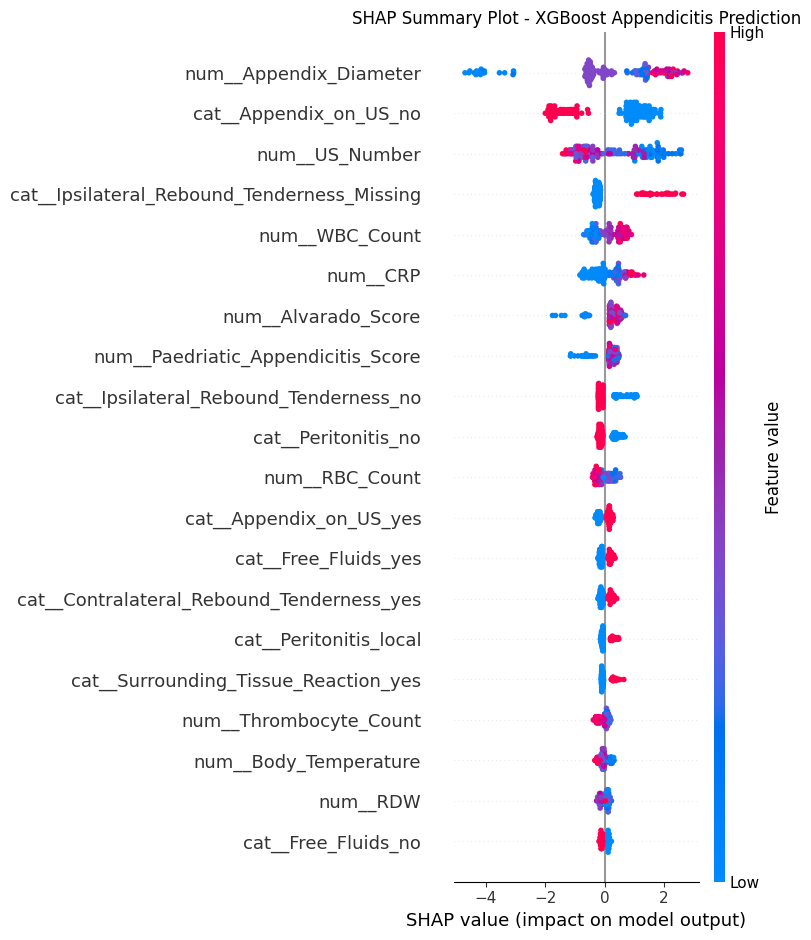

In [ ]:
# STEP 3: SHAP summary plot

import matplotlib.pyplot as plt

# Get processed feature names
feature_names = preprocessor.get_feature_names_out()

# Create SHAP summary plot
shap.summary_plot(
    shap_values.values,
    X_test_processed,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - XGBoost Appendicitis Prediction")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 4: Select one test patient for individual explanation

patient_index = 0

print("Selected test patient index:", patient_index)
print("Actual diagnosis (0 = no appendicitis, 1 = appendicitis):",
      int(y_test.iloc[patient_index]))

print("Predicted class:",
      int(xgboost_model.predict(X_test_processed[patient_index:patient_index+1])[0]))

print("Predicted appendicitis probability:",
      round(
          xgboost_model.predict_proba(
              X_test_processed[patient_index:patient_index+1]
          )[0, 1] * 100, 2
      ), "%")

Selected test patient index: 0
Actual diagnosis (0 = no appendicitis, 1 = appendicitis): 1
Predicted class: 1
Predicted appendicitis probability: 99.81 %


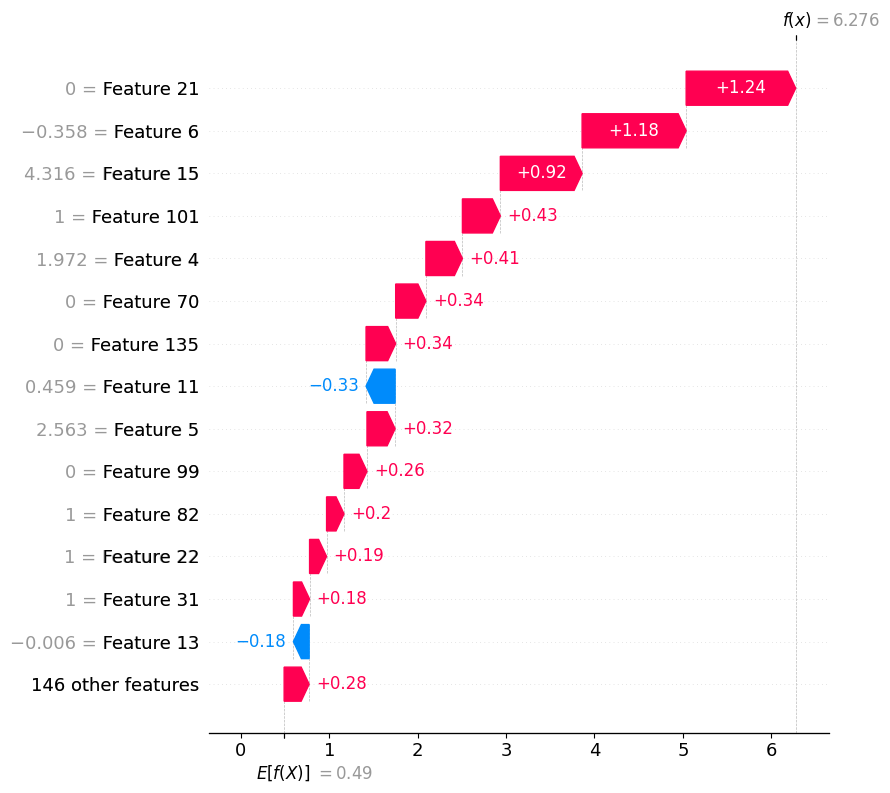

In [ ]:
# SHAP explanation for ONE patient only

patient_index = 0

# Get this patient's SHAP values
single_patient_shap = shap_values[patient_index]

# Get the processed feature names
feature_names = preprocessor.get_feature_names_out()

# Get this patient's processed feature values
patient_data = X_test_processed[patient_index]

# Create a waterfall plot
shap.plots.waterfall(
    single_patient_shap,
    max_display=15
)

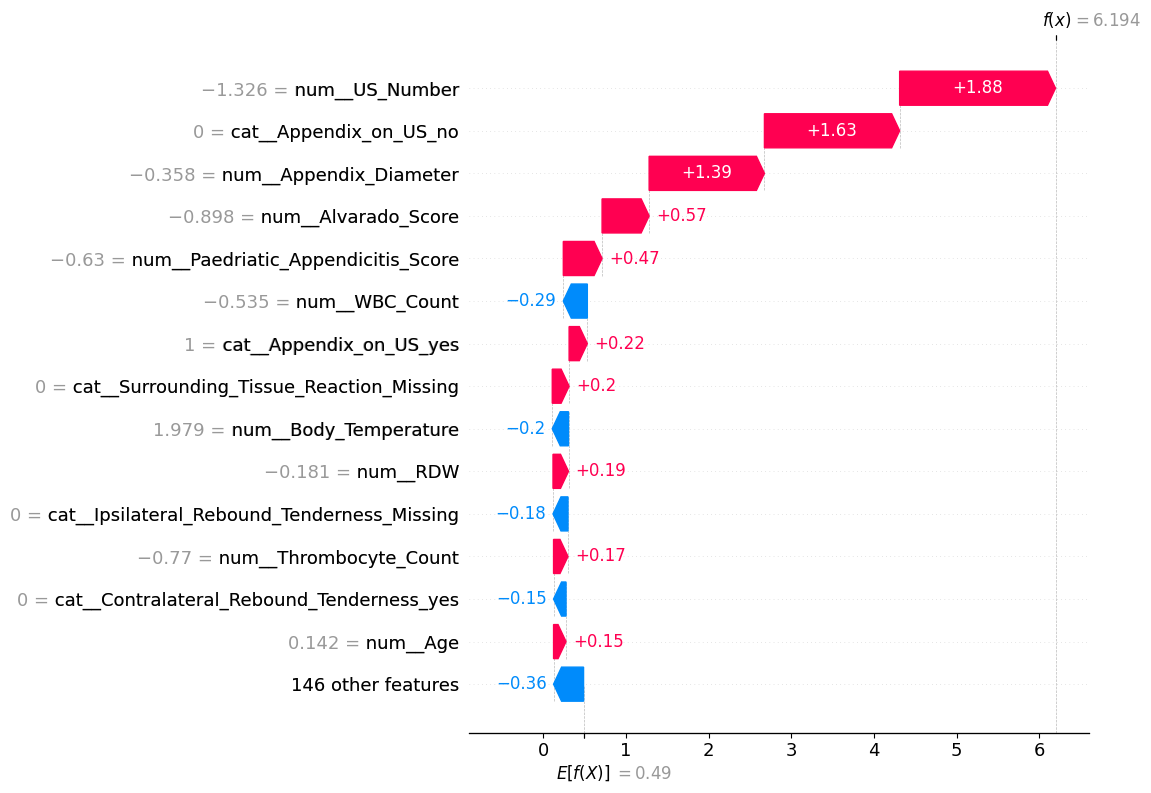

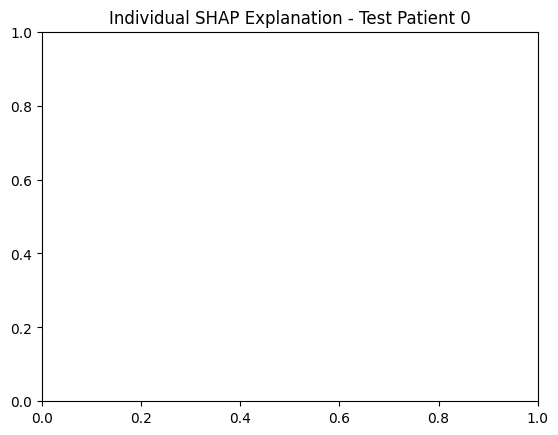

In [ ]:
# Single-patient SHAP waterfall with meaningful feature names

import shap
import numpy as np
import matplotlib.pyplot as plt

patient_index = 1

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get one patient's processed feature values
patient_row = X_test_processed[patient_index]

# Handle either sparse or dense processed data
if hasattr(patient_row, "toarray"):
    patient_row = patient_row.toarray().ravel()
else:
    patient_row = np.asarray(patient_row).ravel()

# Build an explanation with the correct feature names
single_explanation = shap.Explanation(
    values=shap_values.values[patient_index],
    base_values=shap_values.base_values[patient_index],
    data=patient_row,
    feature_names=feature_names
)

# Plot this one patient's explanation
shap.plots.waterfall(
    single_explanation,
    max_display=15
)

plt.title("Individual SHAP Explanation - Test Patient 0")
plt.show()

In [ ]:
!pip install dice-ml -q

import dice_ml

print("DiCE installed successfully!")
print("DiCE version:", getattr(dice_ml, "__version__", "Version not exposed"))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 29.5 MB/s eta 0:00:00
DiCE installed successfully!
DiCE version: Version not exposed


In [ ]:
# STEP 7B: Prepare original clinical data for DiCE

import pandas as pd
import numpy as np

# Keep the original clinical features and target
dice_data = X.copy()
dice_data["Target"] = y

# Identify numerical and categorical feature columns
continuous_features = dice_data.drop(columns=["Target"]).select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in dice_data.drop(columns=["Target"]).columns
    if col not in continuous_features
]

print("DiCE data prepared!")
print("Patient records:", dice_data.shape[0])
print("Clinical input features:", dice_data.shape[1] - 1)
print("Continuous features:", len(continuous_features))
print("Categorical features:", len(categorical_features))
print("\nTarget counts:")
print(dice_data["Target"].value_counts())

DiCE data prepared!
Patient records: 780
Clinical input features: 50
Continuous features: 17
Categorical features: 33

Target counts:
Target
1    463
0    317
Name: count, dtype: int64


In [ ]:
# STEP 7C: Connect DiCE to the existing XGBoost pipeline

import dice_ml
from dice_ml import Dice

from sklearn.base import BaseEstimator, ClassifierMixin

class XGBoostPipelineWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, model, preprocessor):
        self.model = model
        self.preprocessor = preprocessor
        self.classes_ = np.array([0, 1])

    def predict_proba(self, X):
        X = pd.DataFrame(X, columns=candidate_features)
        X_processed = self.preprocessor.transform(X)
        return self.model.predict_proba(X_processed)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# Wrap the trained model and existing preprocessor
dice_model = XGBoostPipelineWrapper(
    model=xgboost_model,
    preprocessor=preprocessor
)

# Define the dataset and target for DiCE
dice_dataset = dice_ml.Data(
    dataframe=dice_data,
    continuous_features=continuous_features,
    outcome_name="Target"
)

# Tell DiCE that the wrapped model is a classifier
dice_backend = dice_ml.Model(
    model=dice_model,
    backend="sklearn",
    model_type="classifier"
)

print("DiCE data interface created successfully!")
print("Existing XGBoost model connected successfully!")

DiCE data interface created successfully!
Existing XGBoost model connected successfully!


In [ ]:

# STEP 7D - Fix missing values in the patient data

# Copy original test patient
patient_original = X_test.iloc[[0]].copy()

# Use imputation rules learned from training data only
patient_original = pd.DataFrame(
    preprocessor.named_transformers_["num"].transform(
        patient_original[continuous_features]
    ),
    columns=continuous_features,
    index=patient_original.index
).join(
    patient_original[categorical_features]
)

print("Missing values after handling:",
      patient_original.isnull().sum().sum())

print("Patient data shape:", patient_original.shape)


Missing values after handling: 8
Patient data shape: (1, 50)


In [ ]:

# STEP 7D - Correctly handle missing values in all features

patient_original = X_test.iloc[[0]].copy()

# Separate numeric and categorical columns
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [col for col in X_train.columns if col not in numeric_cols]

# Apply already-fitted imputers from the preprocessor
patient_original[numeric_cols] = (
    preprocessor.named_transformers_["num"]
    .named_steps["imputer"]
    .transform(patient_original[numeric_cols])
)

patient_original[categorical_cols] = (
    preprocessor.named_transformers_["cat"]
    .named_steps["imputer"]
    .transform(patient_original[categorical_cols])
)

print("Missing values after handling:", patient_original.isnull().sum().sum())
print("Patient data shape:", patient_original.shape)


Missing values after handling: 0
Patient data shape: (1, 50)


In [ ]:

# Check Appendicolith values in dataset and patient

print("Original dataset values:")
print(dice_data["Appendicolith"].value_counts(dropna=False))

print("\nTest patient value:")
print(repr(patient_original["Appendicolith"].iloc[0]))

print("\nTest patient value type:")
print(type(patient_original["Appendicolith"].iloc[0]))


Original dataset values:
Appendicolith
NaN          711
yes           33
no            33
suspected      3
Name: count, dtype: int64

Test patient value:
'Missing'

Test patient value type:
<class 'str'>


In [ ]:

# Standardize missing categorical values in the DiCE dataset

dice_data_fixed = dice_data.copy()

for col in categorical_features:
    dice_data_fixed[col] = dice_data_fixed[col].fillna("Missing").astype(str)

# Ensure the query patient uses the same category format
patient_original_fixed = patient_original.copy()

for col in categorical_features:
    patient_original_fixed[col] = (
        patient_original_fixed[col].fillna("Missing").astype(str)
    )

print("Dataset Appendicolith values:")
print(dice_data_fixed["Appendicolith"].value_counts(dropna=False))

print("\nPatient Appendicolith value:")
print(repr(patient_original_fixed["Appendicolith"].iloc[0]))


Dataset Appendicolith values:
Appendicolith
Missing      711
yes           33
no            33
suspected      3
Name: count, dtype: int64

Patient Appendicolith value:
'Missing'


In [ ]:

# STEP 7H - Recreate DiCE using the corrected dataset

dice_dataset = dice_ml.Data(
    dataframe=dice_data_fixed,
    continuous_features=continuous_features,
    outcome_name="Target"
)

dice_explainer = Dice(
    dice_dataset,
    dice_backend,
    method="random"
)

print("Updated DiCE dataset and explainer ready!")


Updated DiCE dataset and explainer ready!


In [ ]:

# Generate 3 counterfactual examples for the same patient

counterfactuals = dice_explainer.generate_counterfactuals(
    patient_original_fixed,
    total_CFs=3,
    desired_class=0,
    verbose=False
)

print("Counterfactual generation completed!")


100%|██████████| 1/1 [00:00<00:00,  2.28it/s]

Counterfactual generation completed!


In [ ]:

# Display the generated counterfactual examples

counterfactuals.visualize_as_dataframe(show_only_changes=True)


Query instance (original outcome : 1)


,Age,BMI,Sex,Height,Weight,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_on_US,Appendix_Diameter,Migratory_Pain,...,Pathological_Lymph_Nodes,Lymph_Nodes_Location,Bowel_Wall_Thickening,Conglomerate_of_Bowel_Loops,Ileus,Coprostasis,Meteorism,Enteritis,Gynecological_Findings,Target
0,9.57974,14.175849,female,132.0,24.700001,10.0,10.0,yes,7.0,yes,...,no,Missing,Missing,yes,yes,Missing,Missing,Missing,Missing,1



Diverse Counterfactual set (new outcome: 0)


,Age,BMI,Sex,Height,Weight,Alvarado_Score,Paedriatic_Appendicitis_Score,Appendix_on_US,Appendix_Diameter,Migratory_Pain,...,Pathological_Lymph_Nodes,Lymph_Nodes_Location,Bowel_Wall_Thickening,Conglomerate_of_Bowel_Loops,Ileus,Coprostasis,Meteorism,Enteritis,Gynecological_Findings,Target
0,-,21.6,-,-,-,-,-,-,3.5,-,...,-,-,-,-,-,-,-,-,-,0
1,-,-,-,-,-,-,-,-,3.1,-,...,-,-,-,-,-,-,-,-,-,0
2,-,-,-,-,-,-,-,-,3.6,-,...,-,-,-,-,-,-,-,-,-,0


In [ ]:

# STEP 7K - Verify counterfactual predictions

cf_df = counterfactuals.cf_examples_list[0].final_cfs_df.copy()

# Remove the target column if it is present
cf_features = cf_df.drop(columns=["Target"], errors="ignore")

# Predict using the existing XGBoost pipeline wrapper
cf_probabilities = dice_model.predict_proba(cf_features)[:, 1]
cf_predictions = (cf_probabilities >= 0.5).astype(int)

results = pd.DataFrame({
    "Counterfactual": [f"CF{i+1}" for i in range(len(cf_features))],
    "Predicted_Class": cf_predictions,
    "Appendicitis_Probability_%": (cf_probabilities * 100).round(2)
})

print(results)


  Counterfactual  Predicted_Class  Appendicitis_Probability_%
0            CF1                0                   36.560001
1            CF2                0                   36.150002
2            CF3                0                   38.799999


In [ ]:

# STEP 8 - Compare original patient with counterfactuals

original_row = patient_original_fixed.iloc[0]
cf_df = counterfactuals.cf_examples_list[0].final_cfs_df.copy()

# Show only features that changed
for i, cf_row in cf_df.iterrows():
    print(f"\nCounterfactual {i+1}")
    changes = []

    for col in candidate_features:
        original_value = original_row[col]
        cf_value = cf_row[col]

        if pd.isna(original_value) and pd.isna(cf_value):
            continue

        if str(original_value) != str(cf_value):
            changes.append({
                "Feature": col,
                "Original": original_value,
                "Counterfactual": cf_value
            })

    if changes:
        display(pd.DataFrame(changes))
    else:
        print("No feature changes found.")



Counterfactual 1


,Feature,Original,Counterfactual
0,BMI,14.175849,21.6
1,Appendix_Diameter,7.000000,3.5



Counterfactual 2


,Feature,Original,Counterfactual
0,Appendix_Diameter,7.0,3.1
1,US_Number,253.0,990.6



Counterfactual 3


,Feature,Original,Counterfactual
0,Appendix_Diameter,7.0,3.6
1,CRP,278.0,35.7


In [ ]:

# STEP 9 - Compare SHAP importance with DiCE changes

# Average absolute SHAP importance across the test set
shap_importance = np.abs(shap_values.values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Mean_Absolute_SHAP": shap_importance
}).sort_values("Mean_Absolute_SHAP", ascending=False)

print("Top 15 SHAP features:")
display(shap_importance_df.head(15))

print("\nOriginal features changed by DiCE:")
dice_changed_features = set()

for _, cf_row in cf_df.iterrows():
    for col in candidate_features:
        orig_val = patient_original_fixed.iloc[0][col]
        cf_val = cf_row[col]

        if pd.isna(orig_val) and pd.isna(cf_val):
            continue

        if str(orig_val) != str(cf_val):
            dice_changed_features.add(col)

print(sorted(dice_changed_features))


Top 15 SHAP features:


,Encoded_Feature,Mean_Absolute_SHAP
6,num__Appendix_Diameter,1.498400
21,cat__Appendix_on_US_no,1.273446
16,num__US_Number,1.041596
74,cat__Ipsilateral_Rebound_Tenderness_Missing,0.549737
8,num__WBC_Count,0.417713
15,num__CRP,0.402004
4,num__Alvarado_Score,0.395529
5,num__Paedriatic_Appendicitis_Score,0.337465
75,cat__Ipsilateral_Rebound_Tenderness_no,0.271140
70,cat__Peritonitis_no,0.231318



Original features changed by DiCE:
['Appendix_Diameter', 'BMI', 'CRP', 'US_Number']


In [ ]:

# STEP 10 - Inspect US_Number in the original dataset

print("US_Number summary:")
print(df_model["US_Number"].describe())

print("\nFirst 20 distinct values:")
print(df_model["US_Number"].dropna().unique()[:20])

print("\nNumber of distinct values:")
print(df_model["US_Number"].nunique())

print("\nMissing values:")
print(df_model["US_Number"].isna().sum())


US_Number summary:
count    759.000000
mean     425.342556
std      271.722277
min        1.000000
25%      198.500000
50%      398.000000
75%      613.500000
max      992.000000
Name: US_Number, dtype: float64

First 20 distinct values:
[882. 883. 884. 886. 887. 888. 889. 890. 891. 893. 894. 895. 896. 897.
 900. 903. 904. 905. 909. 910.]

Number of distinct values:
759

Missing values:
21


In [ ]:

# STEP 11 - Check US_Number against the target label

print("US_Number vs Target correlation:")
print(df_model[["US_Number", "Target"]].corr(numeric_only=True))

print("\nUS_Number values by target:")
display(
    df_model.groupby("Target")["US_Number"]
    .agg(["count", "mean", "std", "min", "max"])
)

print("\nSample rows:")
display(df_model[["US_Number", "Diagnosis"]].head(15))


US_Number vs Target correlation:
           US_Number    Target
US_Number   1.000000 -0.241541
Target     -0.241541  1.000000

US_Number values by target:


,count,mean,std,min,max
Target,,,,,
0,314,503.423567,255.084817,1.0,991.0
1,445,370.247191,269.859410,2.0,992.0



Sample rows:


,US_Number,Diagnosis
0,882.0,appendicitis
1,883.0,no appendicitis
2,884.0,no appendicitis
3,886.0,no appendicitis
4,887.0,appendicitis
5,888.0,no appendicitis
6,889.0,no appendicitis
7,890.0,no appendicitis
8,891.0,no appendicitis
9,893.0,appendicitis


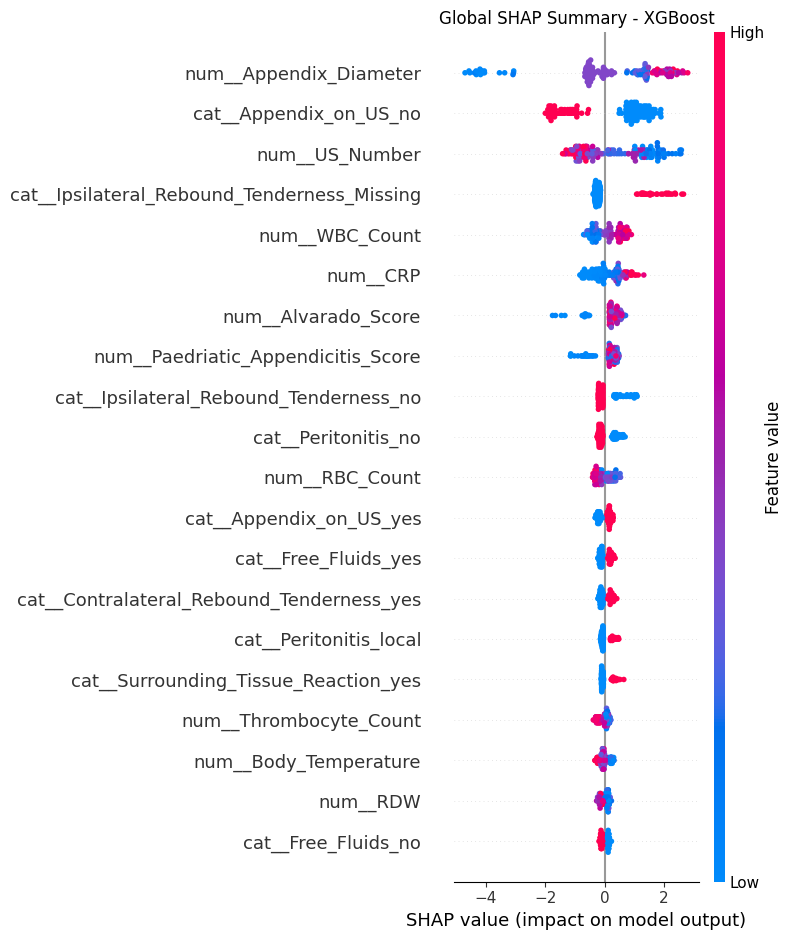

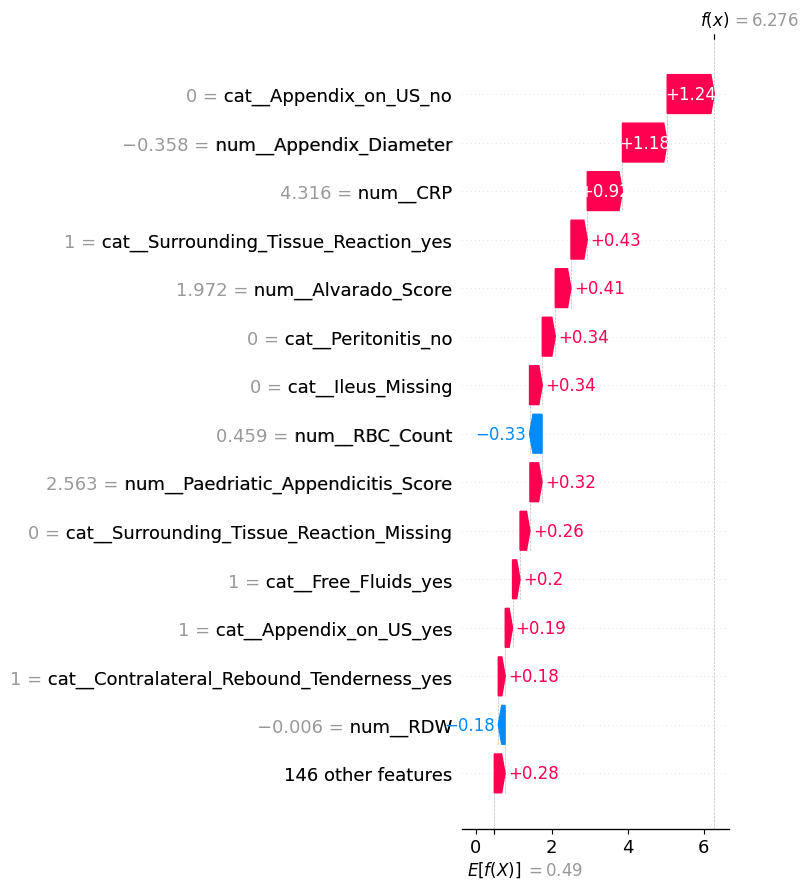

SHAP plots saved successfully!


In [ ]:

# STEP 12 - Save SHAP global and local explanation plots

import matplotlib.pyplot as plt

# 1. Global SHAP summary plot
shap.summary_plot(
    shap_values.values,
    X_test_processed,
    feature_names=feature_names,
    max_display=20,
    show=False
)
plt.title("Global SHAP Summary - XGBoost")
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 2. Local SHAP waterfall plot for patient 0
single_explanation = shap.Explanation(
    values=shap_values.values[0],
    base_values=shap_values.base_values[0],
    data=X_test_processed[0],
    feature_names=feature_names
)

shap.plots.waterfall(single_explanation, max_display=15, show=False)
plt.tight_layout()
plt.savefig("shap_waterfall_patient0.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("SHAP plots saved successfully!")


In [ ]:
# STEP 13 - Final Model Comparison

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Accuracy": [0.9167, 0.9167, 0.9615],
    "Precision": [0.9545, 0.9082, 0.9579],
    "Recall": [0.9032, 0.9570, 0.9785],
    "F1-Score": [0.9282, 0.9319, 0.9681],
    "ROC-AUC": [0.9619, 0.9719, 0.9887]
})

results = results.round(4)

display(results)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.9167,0.9545,0.9032,0.9282,0.9619
1,Random Forest,0.9167,0.9082,0.9570,0.9319,0.9719
2,XGBoost,0.9615,0.9579,0.9785,0.9681,0.9887


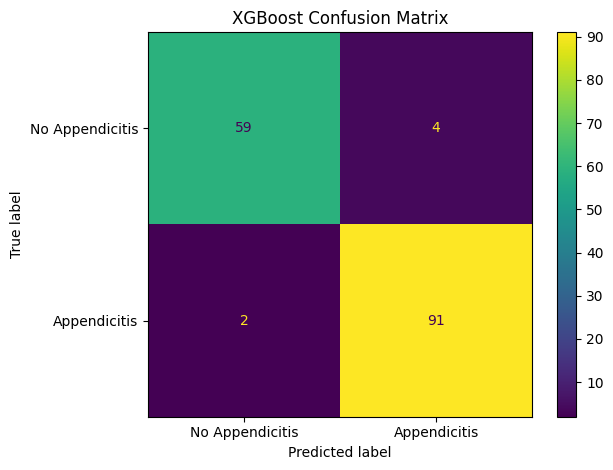

Confusion Matrix:
[[59  4]
 [ 2 91]]


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

y_pred_xgb = xgboost_model.predict(X_test_processed)

cm = confusion_matrix(y_test, y_pred_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Appendicitis", "Appendicitis"]
)

disp.plot(values_format="d")
plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.savefig("xgboost_confusion_matrix.png", dpi=300)
plt.show()

print("Confusion Matrix:")
print(cm)

In [ ]:
# Save model comparison results
results.to_csv("final_model_comparison.csv", index=False)

# Save confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=["Actual_No_Appendicitis", "Actual_Appendicitis"],
    columns=["Predicted_No_Appendicitis", "Predicted_Appendicitis"]
)
cm_df.to_csv("xgboost_confusion_matrix.csv")

print("Final results saved successfully!")
print("1. final_model_comparison.csv")
print("2. xgboost_confusion_matrix.csv")

Final results saved successfully!
1. final_model_comparison.csv
2. xgboost_confusion_matrix.csv


In [ ]:
import joblib
import os

# Create folder for CDSS prototype files
os.makedirs("/content/cdss_model", exist_ok=True)

# Save trained XGBoost model
joblib.dump(
    xgboost_model,
    "/content/cdss_model/xgboost_model.pkl"
)

# Save fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    "/content/cdss_model/preprocessor.pkl"
)

# Save original feature names and their order
joblib.dump(
    candidate_features,
    "/content/cdss_model/feature_names.pkl"
)

print("CDSS model files saved successfully!")
print(os.listdir("/content/cdss_model"))

CDSS model files saved successfully!
['xgboost_model.pkl', 'preprocessor.pkl', 'feature_names.pkl']


In [ ]:
import shutil
from google.colab import files

# Pack all saved model files into one ZIP
zip_path = shutil.make_archive(
    "/content/cdss_model",
    "zip",
    "/content/cdss_model"
)

print("ZIP file created:", zip_path)

# Download to your computer
files.download(zip_path)

ZIP file created: /content/cdss_model.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/cdss_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install -q streamlit shap joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 42.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 56.3 MB/s eta 0:00:00


In [ ]:
%%writefile /content/app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import shap

st.set_page_config(
    page_title="Pediatric Appendicitis CDSS",
    page_icon="🩺",
    layout="wide"
)

@st.cache_resource
def load_artifacts():
    model = joblib.load("/content/cdss_model/xgboost_model.pkl")
    preprocessor = joblib.load("/content/cdss_model/preprocessor.pkl")
    feature_names = joblib.load("/content/cdss_model/feature_names.pkl")
    return model, preprocessor, feature_names

model, preprocessor, feature_names = load_artifacts()

st.title("🩺 Pediatric Appendicitis Decision Support")
st.caption("Research prototype — not for standalone clinical diagnosis.")

st.warning(
    "This prototype is for research and demonstration only. "
    "It is not clinically validated and must not guide real-patient "
    "care without appropriate clinical validation and oversight."
)

st.subheader("Patient information")
st.write(
    "Indha first prototype-la, model-ku thevaiyaana original dataset "
    "features-ai enter pannuvom. Correct feature values and categories "
    "dataset-la use pannina format-oda match aaganum."
)

st.info(
    "Next step-la dataset-based input form create pannuvom. "
    "Categorical options and numeric ranges-ai original dataset-lendhu "
    "derive pannradhu mukkiyam; random options use panna koodadhu."
)

st.success("Model and preprocessing pipeline loaded successfully.")
st.write(f"Expected patient input features: **{len(feature_names)}**")

Writing /content/app.py


In [ ]:
# Check all input features and their data types
print("Total features:", len(candidate_features))

for col in candidate_features:
    print(f"{col}  -->  {X[col].dtype}")

Total features: 50
Age  -->  float64
BMI  -->  float64
Sex  -->  object
Height  -->  float64
Weight  -->  float64
Alvarado_Score  -->  float64
Paedriatic_Appendicitis_Score  -->  float64
Appendix_on_US  -->  object
Appendix_Diameter  -->  float64
Migratory_Pain  -->  object
Lower_Right_Abd_Pain  -->  object
Contralateral_Rebound_Tenderness  -->  object
Coughing_Pain  -->  object
Nausea  -->  object
Loss_of_Appetite  -->  object
Body_Temperature  -->  float64
WBC_Count  -->  float64
Neutrophil_Percentage  -->  float64
Segmented_Neutrophils  -->  float64
Neutrophilia  -->  object
RBC_Count  -->  float64
Hemoglobin  -->  float64
RDW  -->  float64
Thrombocyte_Count  -->  float64
Ketones_in_Urine  -->  object
RBC_in_Urine  -->  object
WBC_in_Urine  -->  object
CRP  -->  float64
Dysuria  -->  object
Stool  -->  object
Peritonitis  -->  object
Psoas_Sign  -->  object
Ipsilateral_Rebound_Tenderness  -->  object
US_Performed  -->  object
US_Number  -->  float64
Free_Fluids  -->  object
Appendix

In [ ]:
# STEP 20 - Train a separate Top 10 feature model

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier
import pandas as pd

top10_features = [
    "Appendix_Diameter",
    "Appendix_on_US",
    "Ipsilateral_Rebound_Tenderness",
    "WBC_Count",
    "CRP",
    "Alvarado_Score",
    "Paedriatic_Appendicitis_Score",
    "Peritonitis",
    "RBC_Count",
    "Free_Fluids"
]

top10_numeric = X_train[top10_features].select_dtypes(
    include="number"
).columns.tolist()

top10_categorical = [
    col for col in top10_features if col not in top10_numeric
]

top10_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), top10_numeric),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), top10_categorical)
])

X_train_top10 = X_train[top10_features]
X_test_top10 = X_test[top10_features]

X_train_top10_processed = top10_preprocessor.fit_transform(X_train_top10)
X_test_top10_processed = top10_preprocessor.transform(X_test_top10)

top10_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

top10_model.fit(X_train_top10_processed, y_train)

top10_pred = top10_model.predict(X_test_top10_processed)
top10_prob = top10_model.predict_proba(X_test_top10_processed)[:, 1]

top10_results = pd.DataFrame([{
    "Model": "XGBoost - Top 10 Features",
    "Accuracy": accuracy_score(y_test, top10_pred),
    "Precision": precision_score(y_test, top10_pred),
    "Recall": recall_score(y_test, top10_pred),
    "F1-Score": f1_score(y_test, top10_pred),
    "ROC-AUC": roc_auc_score(y_test, top10_prob)
}]).round(4)

display(top10_results)
print("Top 10 feature model trained successfully.")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost - Top 10 Features,0.9359,0.9462,0.9462,0.9462,0.9753


Top 10 feature model trained successfully.


In [ ]:
# Compare Full model and Top 10 model

comparison = pd.DataFrame([
    {
        "Model": "XGBoost - Full 50 Features",
        "Accuracy": accuracy_score(y_test, xgboost_model.predict(X_test_processed)),
        "Precision": precision_score(y_test, xgboost_model.predict(X_test_processed)),
        "Recall": recall_score(y_test, xgboost_model.predict(X_test_processed)),
        "F1-Score": f1_score(y_test, xgboost_model.predict(X_test_processed)),
        "ROC-AUC": roc_auc_score(
            y_test,
            xgboost_model.predict_proba(X_test_processed)[:, 1]
        )
    },
    {
        "Model": "XGBoost - Top 10 Features",
        "Accuracy": accuracy_score(y_test, top10_pred),
        "Precision": precision_score(y_test, top10_pred),
        "Recall": recall_score(y_test, top10_pred),
        "F1-Score": f1_score(y_test, top10_pred),
        "ROC-AUC": roc_auc_score(y_test, top10_prob)
    }
])

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost - Full 50 Features,0.9615,0.9579,0.9785,0.9681,0.9887
1,XGBoost - Top 10 Features,0.9359,0.9462,0.9462,0.9462,0.9753


In [ ]:
import joblib
import os

model_dir = "/content/cdss_model"
os.makedirs(model_dir, exist_ok=True)

joblib.dump(top10_model, f"{model_dir}/top10_model.pkl")
joblib.dump(top10_preprocessor, f"{model_dir}/top10_preprocessor.pkl")
joblib.dump(top10_features, f"{model_dir}/top10_features.pkl")

# Save comparison results too
comparison.to_csv("/content/final_model_comparison_full_vs_top10.csv", index=False)

print("Top 10 model and preprocessor saved!")
print(os.listdir(model_dir))

Top 10 model and preprocessor saved!
['top10_features.pkl', 'top10_preprocessor.pkl', 'xgboost_model.pkl', 'top10_model.pkl', 'preprocessor.pkl', 'feature_names.pkl']


In [ ]:
%%writefile /content/app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import shap

st.set_page_config(
    page_title="Pediatric Appendicitis CDSS",
    page_icon="🩺",
    layout="wide"
)

MODEL_DIR = "/content/cdss_model"

@st.cache_resource
def load_models():
    full_model = joblib.load(f"{MODEL_DIR}/xgboost_model.pkl")
    full_preprocessor = joblib.load(f"{MODEL_DIR}/preprocessor.pkl")
    full_features = joblib.load(f"{MODEL_DIR}/feature_names.pkl")

    top_model = joblib.load(f"{MODEL_DIR}/top10_model.pkl")
    top_preprocessor = joblib.load(f"{MODEL_DIR}/top10_preprocessor.pkl")
    top_features = joblib.load(f"{MODEL_DIR}/top10_features.pkl")

    return (
        full_model, full_preprocessor, full_features,
        top_model, top_preprocessor, top_features
    )

(
    full_model, full_preprocessor, full_features,
    top_model, top_preprocessor, top_features
) = load_models()

st.title("🩺 Pediatric Appendicitis Decision Support")
st.caption("Explainable ML Research Prototype")

st.warning(
    "Research use only — not clinically validated. "
    "This tool must not be used as a standalone diagnosis or to "
    "make real-patient treatment decisions."
)

mode = st.radio(
    "Choose prediction mode",
    ["Quick Prediction — Top 10 Features",
     "Full Prediction — 50 Features"],
    horizontal=True
)

if mode.startswith("Quick"):
    model = top_model
    preprocessor = top_preprocessor
    features = top_features
else:
    model = full_model
    preprocessor = full_preprocessor
    features = full_features

st.subheader("Patient information")
st.write(f"Selected model uses **{len(features)} features**.")

numeric_features = [
    f for f in features
    if pd.api.types.is_numeric_dtype(X[f])
]
categorical_features = [f for f in features if f not in numeric_features]

# Use dataset-derived values and categories
patient_data = {}

with st.form("patient_form"):
    st.subheader("Numeric features")
    numeric_cols = st.columns(2)

    for i, feature in enumerate(numeric_features):
        vals = pd.to_numeric(X[feature], errors="coerce").dropna()
        default_value = float(vals.median()) if not vals.empty else 0.0

        patient_data[feature] = numeric_cols[i % 2].number_input(
            feature.replace("_", " "),
            value=default_value,
            key=f"num_{feature}"
        )

    st.subheader("Categorical features")
    categorical_cols = st.columns(2)

    for i, feature in enumerate(categorical_features):
        categories = sorted(X[feature].dropna().astype(str).unique().tolist())
        options = ["Missing"] + categories

        patient_data[feature] = categorical_cols[i % 2].selectbox(
            feature.replace("_", " "),
            options=options,
            index=0,
            key=f"cat_{feature}"
        )

    submitted = st.form_submit_button("Generate model prediction")

if submitted:
    patient_df = pd.DataFrame([patient_data], columns=features)

    # Convert categorical Missing values to actual missing values
    for feature in categorical_features:
        if patient_df.loc[0, feature] == "Missing":
            patient_df.loc[0, feature] = np.nan

    processed = preprocessor.transform(patient_df)
    probability = float(model.predict_proba(processed)[0, 1])
    predicted_class = int(model.predict(processed)[0])

    st.subheader("Model output")
    st.metric("Model-estimated appendicitis probability", f"{probability:.1%}")

    if predicted_class == 1:
        st.error("Model class: Appendicitis")
    else:
        st.info("Model class: No appendicitis")

    st.caption(
        "This is a model estimate, not an individual's confirmed clinical risk "
        "or diagnosis. Interpret with a qualified healthcare professional."
    )

    st.subheader("SHAP explanation")
    try:
        explainer = shap.TreeExplainer(model)
        shap_values = explainer(processed)

        st.write("Features contributing most to this model output:")
        contributions = pd.DataFrame({
            "Feature": features if len(features) == len(shap_values.values[0]) else
                       [f"Encoded feature {i+1}" for i in range(shap_values.values.shape[1])],
            "SHAP contribution": shap_values.values[0]
        })
        contributions["Absolute contribution"] = contributions["SHAP contribution"].abs()
        st.dataframe(
            contributions.sort_values("Absolute contribution", ascending=False)
                         .drop(columns=["Absolute contribution"])
                         .head(10),
            use_container_width=True
        )
    except Exception as exc:
        st.warning(f"SHAP explanation could not be generated: {exc}")

st.divider()
st.caption(
    "Prototype limitation: training/test data and independent clinical validation "
    "must be reviewed before any real-world use."
)

Overwriting /content/app.py


In [ ]:
!pip -q install streamlit
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙
added 22 packages in 4s
⠙
⠙3 packages are looking for funding
⠙  run `npm fund` for details
⠙

In [ ]:
import joblib

joblib.dump(X, "/content/cdss_model/training_features.pkl")

print("✅ Training feature data saved!")
print("Dataset shape:", X.shape)
print("Next: dashboard code-la small update pannuvom.")

✅ Training feature data saved!
Dataset shape: (780, 50)
Next: dashboard code-la small update pannuvom.


In [ ]:
%%writefile /content/fix_app.py
from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

code = code.replace(
    'MODEL_DIR = "/content/cdss_model"',
    'MODEL_DIR = "/content/cdss_model"\nX = joblib.load(f"{MODEL_DIR}/training_features.pkl")'
)

app_path.write_text(code)

print("✅ Dashboard code updated!")
print("X loaded from saved training features.")

Writing /content/fix_app.py


In [ ]:
from pathlib import Path
import joblib

app_path = Path("/content/app.py")
code = app_path.read_text()

code = code.replace(
    'MODEL_DIR = "/content/cdss_model"',
    'MODEL_DIR = "/content/cdss_model"\nX = joblib.load(f"{MODEL_DIR}/training_features.pkl")'
)

app_path.write_text(code)

print("✅ Original app.py updated!")
print("Dataset loaded:", joblib.load(
    "/content/cdss_model/training_features.pkl"
).shape)

✅ Original app.py updated!
Dataset loaded: (780, 50)


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
import requests
import time

time.sleep(3)

try:
    response = requests.get("http://127.0.0.1:8501", timeout=5)

    if response.status_code == 200:
        print("✅ Streamlit dashboard running!")
        print("Status code:", response.status_code)
    else:
        print("⚠️ Server responded with:", response.status_code)

except Exception as e:
    print("❌ Server connection failed:", e)

print("\n--- Streamlit log ---")
!tail -30 /content/streamlit.log

✅ Streamlit dashboard running!
Status code: 200

--- Streamlit log ---


2026-10-20 13:51:23.581 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.73.29.88:8501



In [ ]:

# STEP 1: Check research prototype environment

import os
import importlib.util
import pandas as pd
import numpy as np
import joblib

print("Dataset available:", os.path.exists("/content/app_data.xlsx"))
print("Saved models available:", os.path.exists("/content/cdss_model"))
print("SHAP installed:", importlib.util.find_spec("shap") is not None)
print("DiCE installed:", importlib.util.find_spec("dice_ml") is not None)

if os.path.exists("/content/app_data.xlsx"):
    df_check = pd.read_excel("/content/app_data.xlsx")
    print("Original dataset shape:", df_check.shape)

if os.path.exists("/content/cdss_model"):
    print("Saved model files:", os.listdir("/content/cdss_model"))


Dataset available: True
Saved models available: True
SHAP installed: True
DiCE installed: True
Original dataset shape: (782, 58)
Saved model files: ['top10_features.pkl', 'top10_preprocessor.pkl', 'xgboost_model.pkl', 'top10_model.pkl', 'preprocessor.pkl', 'training_features.pkl', 'feature_names.pkl']


In [ ]:

# STEP 2: Load saved models and prepare dataset

import pandas as pd
import numpy as np
import joblib
import shap
import dice_ml

MODEL_DIR = "/content/cdss_model"

# Load original dataset
df = pd.read_excel("/content/app_data.xlsx")

# Remove rows without diagnosis
df = df.dropna(subset=["Diagnosis"]).copy()

# Encode target: 0 = No appendicitis, 1 = Appendicitis
df["Target"] = (
    df["Diagnosis"].astype(str).str.strip().str.lower()
    .map({
        "appendicitis": 1,
        "no appendicitis": 0
    })
)

print("Diagnosis labels:", df["Diagnosis"].value_counts().to_dict())

# Load saved models and preprocessing objects
full_model = joblib.load(f"{MODEL_DIR}/xgboost_model.pkl")
full_preprocessor = joblib.load(f"{MODEL_DIR}/preprocessor.pkl")
full_features = joblib.load(f"{MODEL_DIR}/feature_names.pkl")

top10_model = joblib.load(f"{MODEL_DIR}/top10_model.pkl")
top10_preprocessor = joblib.load(f"{MODEL_DIR}/top10_preprocessor.pkl")
top10_features = joblib.load(f"{MODEL_DIR}/top10_features.pkl")

# Verify
print("\n✅ Models loaded successfully")
print("Full model features:", len(full_features))
print("Top 10 model features:", len(top10_features))
print("Valid diagnosis rows:", df["Target"].notna().sum())
print("\nTop 10 features:")
print(top10_features)


Diagnosis labels: {'appendicitis': 463, 'no appendicitis': 317}

✅ Models loaded successfully
Full model features: 50
Top 10 model features: 10
Valid diagnosis rows: 780

Top 10 features:
['Appendix_Diameter', 'Appendix_on_US', 'Ipsilateral_Rebound_Tenderness', 'WBC_Count', 'CRP', 'Alvarado_Score', 'Paedriatic_Appendicitis_Score', 'Peritonitis', 'RBC_Count', 'Free_Fluids']


In [ ]:

# STEP 3: Test prediction using one held-out dataset example
# Research demonstration only — not for real-patient diagnosis.

# Select one example from the dataset
sample_row = df[df["Target"].notna()].iloc[0]

# Keep only features required by each model
full_patient = sample_row[full_features].to_frame().T
top10_patient = sample_row[top10_features].to_frame().T

# Apply saved preprocessing
full_processed = full_preprocessor.transform(full_patient)
top10_processed = top10_preprocessor.transform(top10_patient)

# Predict
full_probability = full_model.predict_proba(full_processed)[0, 1]
full_prediction = int(full_model.predict(full_processed)[0])

top10_probability = top10_model.predict_proba(top10_processed)[0, 1]
top10_prediction = int(top10_model.predict(top10_processed)[0])

results = pd.DataFrame([
    {
        "Model": "Full model (50 features)",
        "Predicted class": (
            "Appendicitis" if full_prediction == 1 else "No appendicitis"
        ),
        "Model-estimated probability": round(float(full_probability), 4)
    },
    {
        "Model": "Top 10 model",
        "Predicted class": (
            "Appendicitis" if top10_prediction == 1 else "No appendicitis"
        ),
        "Model-estimated probability": round(float(top10_probability), 4)
    }
])

print("Sample's dataset label:",
      "Appendicitis" if sample_row["Target"] == 1 else "No appendicitis")
display(results)


Sample's dataset label: Appendicitis


,Model,Predicted class,Model-estimated probability
0,Full model (50 features),Appendicitis,0.953
1,Top 10 model,Appendicitis,0.851


In [ ]:

%pip -q install ipywidgets dice-ml shap xgboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 36.7 MB/s eta 0:00:00


In [ ]:

import pandas as pd
import numpy as np
import joblib
import shap
import dice_ml
import ipywidgets as widgets
from IPython.display import display, clear_output

# Reuse existing dataset and saved models
df = pd.read_excel("/content/app_data.xlsx")
MODEL_DIR = "/content/cdss_model"

full_model = joblib.load(f"{MODEL_DIR}/xgboost_model.pkl")
full_preprocessor = joblib.load(f"{MODEL_DIR}/preprocessor.pkl")
full_features = joblib.load(f"{MODEL_DIR}/feature_names.pkl")

top10_model = joblib.load(f"{MODEL_DIR}/top10_model.pkl")
top10_preprocessor = joblib.load(f"{MODEL_DIR}/top10_preprocessor.pkl")
top10_features = joblib.load(f"{MODEL_DIR}/top10_features.pkl")

print("✅ Interactive prototype setup ready")
print("Dataset:", df.shape)
print("Full model features:", len(full_features))
print("Top 10 model features:", len(top10_features))
print("ipywidgets version:", widgets.__version__)


✅ Interactive prototype setup ready
Dataset: (782, 58)
Full model features: 50
Top 10 model features: 10
ipywidgets version: 7.7.1


In [ ]:

# COMPLETE PEDIATRIC APPENDICITIS RESEARCH PROTOTYPE
# Run this as ONE cell in Google Colab.
# Research/demo only — not clinically validated.

import io
import numpy as np
import pandas as pd
import joblib
import shap
import ipywidgets as widgets
from IPython.display import display, clear_output

# --------------------------------------------------
# 1. LOAD EXISTING DATASET, MODELS AND PREPROCESSORS
# --------------------------------------------------

MODEL_DIR = "/content/cdss_model"

source_df = pd.read_excel("/content/app_data.xlsx")
reference_X = joblib.load(f"{MODEL_DIR}/training_features.pkl")

full_model = joblib.load(f"{MODEL_DIR}/xgboost_model.pkl")
full_preprocessor = joblib.load(f"{MODEL_DIR}/preprocessor.pkl")
full_features = list(joblib.load(f"{MODEL_DIR}/feature_names.pkl"))

top10_model = joblib.load(f"{MODEL_DIR}/top10_model.pkl")
top10_preprocessor = joblib.load(f"{MODEL_DIR}/top10_preprocessor.pkl")
top10_features = list(joblib.load(f"{MODEL_DIR}/top10_features.pkl"))

# --------------------------------------------------
# 2. USER INTERFACE
# --------------------------------------------------

model_select = widgets.Dropdown(
    options=[
        ("Quick model — Top 10 features", "top10"),
        ("Full model — 50 features", "full")
    ],
    value="top10",
    description="Model:",
    layout=widgets.Layout(width="370px")
)

mode_select = widgets.Dropdown(
    options=[
        ("Manual patient input", "manual"),
        ("Upload patient dataset", "upload")
    ],
    value="manual",
    description="Input:",
    layout=widgets.Layout(width="370px")
)

file_upload = widgets.FileUpload(
    accept=".csv,.xlsx,.xls",
    multiple=False,
    description="Choose file"
)

numeric_inputs = {}
category_inputs = {}

form_box = widgets.VBox()
manual_box = widgets.VBox()
upload_box = widgets.VBox([
    widgets.HTML(
        "<b>Upload patient dataset</b><br>"
        "One row per patient. Column names must match the selected model's features."
    ),
    file_upload
])

run_button = widgets.Button(
    description="Predict + Explain",
    button_style="primary",
    icon="check"
)

output_box = widgets.Output()
download_box = widgets.VBox()

# --------------------------------------------------
# 3. MODEL / FEATURE HELPERS
# --------------------------------------------------

def get_selected_objects():
    if model_select.value == "top10":
        return top10_model, top10_preprocessor, top10_features
    return full_model, full_preprocessor, full_features

def rebuild_form(*args):
    numeric_inputs.clear()
    category_inputs.clear()

    _, _, features = get_selected_objects()
    controls = []

    for feature in features:
        if feature not in reference_X.columns:
            continue

        series = reference_X[feature]

        if pd.api.types.is_numeric_dtype(series):
            vals = pd.to_numeric(series, errors="coerce").dropna()
            default = float(vals.median()) if not vals.empty else 0.0

            control = widgets.FloatText(
                value=default,
                description=feature.replace("_", " "),
                style={"description_width": "initial"},
                layout=widgets.Layout(width="430px")
            )
            numeric_inputs[feature] = control

        else:
            choices = sorted(series.dropna().astype(str).unique().tolist())

            control = widgets.Dropdown(
                options=["Missing"] + choices,
                value="Missing",
                description=feature.replace("_", " "),
                style={"description_width": "initial"},
                layout=widgets.Layout(width="430px")
            )
            category_inputs[feature] = control

        controls.append(control)

    form_box.children = tuple(controls)
    manual_box.children = (
        widgets.HTML(
            f"<h4>Patient details ({len(features)} features)</h4>"
        ),
        form_box
    )

def switch_mode(*args):
    manual_box.layout.display = (
        "block" if mode_select.value == "manual" else "none"
    )
    upload_box.layout.display = (
        "block" if mode_select.value == "upload" else "none"
    )

model_select.observe(rebuild_form, names="value")
mode_select.observe(switch_mode, names="value")

rebuild_form()
switch_mode()

# --------------------------------------------------
# 4. LOAD MULTI-PATIENT CSV / EXCEL
# --------------------------------------------------

def read_uploaded_dataset():
    uploaded = file_upload.value

    if not uploaded:
        raise ValueError("Please upload a CSV or Excel file first.")

    if isinstance(uploaded, dict):
        item = next(iter(uploaded.values()))
        filename = item.get("metadata", {}).get("name", "patients.csv")
        content = bytes(item["content"])
    else:
        item = uploaded[0]
        filename = item["name"]
        content = bytes(item["content"])

    if filename.lower().endswith(".csv"):
        return pd.read_csv(io.BytesIO(content))

    return pd.read_excel(io.BytesIO(content))

def prepare_patient_data(data, features):
    missing = [f for f in features if f not in data.columns]

    if missing:
        raise ValueError(
            "Uploaded file is missing these required columns: "
            + ", ".join(missing)
        )

    clean = data[features].copy()

    for feature in features:
        if pd.api.types.is_numeric_dtype(reference_X[feature]):
            clean[feature] = pd.to_numeric(
                clean[feature], errors="coerce"
            )
        else:
            clean[feature] = clean[feature].apply(
                lambda value: np.nan
                if pd.isna(value) or str(value).strip().lower()
                in {"", "missing", "nan", "none"}
                else str(value)
            )

    return clean

# --------------------------------------------------
# 5. SHAP EXPLANATION HELPER
# --------------------------------------------------

def get_shap_values(model, processed, preprocessor):
    explainer = shap.TreeExplainer(model)
    shap_output = explainer.shap_values(processed)

    if isinstance(shap_output, list):
        values = np.asarray(
            shap_output[1] if len(shap_output) > 1 else shap_output[0]
        )
    else:
        values = np.asarray(shap_output)

        if values.ndim == 3:
            values = (
                values[:, :, 1]
                if values.shape[-1] == 2
                else values[:, :, 0]
            )

    values = np.atleast_2d(values)

    try:
        names = list(preprocessor.get_feature_names_out())
    except Exception:
        names = [
            f"Encoded feature {i+1}"
            for i in range(values.shape[1])
        ]

    if len(names) != values.shape[1]:
        names = [
            f"Encoded feature {i+1}"
            for i in range(values.shape[1])
        ]

    return values, names

# --------------------------------------------------
# 6. RUN PREDICTION ONLY WHEN BUTTON IS CLICKED
# --------------------------------------------------

def run_analysis(_):
    with output_box:
        clear_output(wait=True)
        download_box.children = ()

        try:
            model, preprocessor, features = get_selected_objects()

            # Gather manual input OR uploaded dataset
            if mode_select.value == "manual":
                patient_values = {}

                for feature, control in numeric_inputs.items():
                    patient_values[feature] = control.value

                for feature, control in category_inputs.items():
                    patient_values[feature] = (
                        np.nan if control.value == "Missing"
                        else control.value
                    )

                raw_data = pd.DataFrame(
                    [patient_values], columns=features
                )

            else:
                uploaded_data = read_uploaded_dataset()

                # Explicitly ignore known outcome columns
                excluded = {
                    "diagnosis", "diagnosis_presumptive", "target",
                    "management", "severity", "length_of_stay",
                    "perforation", "appendicular_abscess"
                }

                ignored = [
                    c for c in uploaded_data.columns
                    if str(c).strip().lower() in excluded
                ]

                if ignored:
                    print("Outcome columns ignored:", ", ".join(ignored))

                raw_data = prepare_patient_data(uploaded_data, features)

            raw_data = prepare_patient_data(raw_data, features)

            if raw_data.empty:
                raise ValueError("No patient records found in the input.")

            # Predict
            processed = preprocessor.transform(raw_data)
            probabilities = model.predict_proba(processed)[:, 1]
            predictions = model.predict(processed).astype(int)

            results = pd.DataFrame({
                "Patient": [
                    f"Patient {i+1}" for i in range(len(raw_data))
                ],
                "Predicted class": [
                    "Appendicitis" if p == 1 else "No appendicitis"
                    for p in predictions
                ],
                "Appendicitis (%)": np.round(probabilities * 100, 2),
                "No appendicitis (%)": np.round(
                    (1 - probabilities) * 100, 2
                )
            })

            print("PATIENT PREDICTION RESULTS")
            display(results)

            print(
                "Percentages are model-estimated probabilities, "
                "not confirmed clinical risks."
            )

            # Individual SHAP explanations for every patient
            shap_values, shap_names = get_shap_values(
                model, processed, preprocessor
            )

            all_shap_tables = []
            summary_rows = []

            for i in range(len(raw_data)):
                patient_name = f"Patient {i+1}"

                table = pd.DataFrame({
                    "Feature": shap_names,
                    "SHAP contribution": shap_values[i]
                })

                table["Direction"] = np.where(
                    table["SHAP contribution"] > 0,
                    "Pushes toward appendicitis",
                    np.where(
                        table["SHAP contribution"] < 0,
                        "Pushes away from appendicitis",
                        "No contribution"
                    )
                )

                table["Absolute contribution"] = (
                    table["SHAP contribution"].abs()
                )

                table = table.sort_values(
                    "Absolute contribution", ascending=False
                )

                print(f"\n{patient_name} — SHAP contributions")
                display(
                    table.head(10)[
                        ["Feature", "SHAP contribution", "Direction"]
                    ]
                )

                exported = table.copy()
                exported.insert(0, "Patient", patient_name)
                all_shap_tables.append(exported)

                summary_rows.append({
                    "Patient": patient_name,
                    "Positive contribution total": table.loc[
                        table["SHAP contribution"] > 0,
                        "SHAP contribution"
                    ].sum(),
                    "Negative contribution total": table.loc[
                        table["SHAP contribution"] < 0,
                        "SHAP contribution"
                    ].sum(),
                    "Net SHAP contribution": table[
                        "SHAP contribution"
                    ].sum(),
                    "Absolute contribution total": table[
                        "Absolute contribution"
                    ].sum()
                })

            contribution_summary = pd.DataFrame(summary_rows)

            print("\nTOTAL SHAP CONTRIBUTION SUMMARY")
            display(contribution_summary.round(4))

            # Store results for further analysis / counterfactuals
            globals()["last_patient_inputs"] = raw_data.copy()
            globals()["last_patient_predictions"] = results.copy()
            globals()["last_patient_shap_tables"] = pd.concat(
                all_shap_tables, ignore_index=True
            )
            globals()["last_contribution_summary"] = (
                contribution_summary.copy()
            )
            globals()["last_patient_processed"] = processed
            globals()["last_patient_shap_values"] = shap_values
            globals()["last_model_choice"] = model_select.value
            globals()["last_model_object"] = model
            globals()["last_preprocessor_object"] = preprocessor

            # Download controls appear only after successful prediction
            shap_export = globals()["last_patient_shap_tables"]

            download_box.children = (
                widgets.FileDownload(
                    data=results.to_csv(index=False).encode("utf-8"),
                    filename="patient_predictions.csv",
                    description="Download predictions"
                ),
                widgets.FileDownload(
                    data=shap_export.to_csv(index=False).encode("utf-8"),
                    filename="patient_shap_contributions.csv",
                    description="Download SHAP details"
                ),
                widgets.FileDownload(
                    data=contribution_summary.to_csv(
                        index=False
                    ).encode("utf-8"),
                    filename="shap_contribution_summary.csv",
                    description="Download SHAP summary"
                )
            )

            display(download_box)

        except Exception as exc:
            print("Unable to complete prediction:", repr(exc))

run_button.on_click(run_analysis)

# --------------------------------------------------
# 7. SHOW THE FORM ONLY — NO PREDICTION UNTIL CLICK
# --------------------------------------------------

display(widgets.VBox([
    widgets.HTML(
        "<h3>Pediatric Appendicitis Research Prototype</h3>"
        "<p><b>Research use only — not clinically validated.</b></p>"
    ),
    model_select,
    mode_select,
    manual_box,
    upload_box,
    run_button,
    output_box
]))


In [ ]:
[name for name in globals()
 if any(k in name.lower()
        for k in ["lr", "logistic", "rf", "forest", "xgb"])]

['LogisticRegression',
 'logistic_model',
 'y_pred_lr',
 'y_prob_lr',
 'lr_accuracy',
 'lr_precision',
 'lr_recall',
 'lr_f1',
 'lr_roc_auc',
 'RandomForestClassifier',
 'random_forest_model',
 'y_pred_rf',
 'y_prob_rf',
 'rf_accuracy',
 'rf_precision',
 'rf_recall',
 'rf_f1',
 'rf_roc_auc',
 'XGBClassifier',
 'xgboost_model',
 'y_pred_xgb',
 'y_prob_xgb',
 'xgb_accuracy',
 'xgb_precision',
 'xgb_recall',
 'xgb_f1',
 'xgb_roc_auc',
 'XGBoostPipelineWrapper',
 'counterfactuals']

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,91.67%,95.45%,90.32%,92.82%,96.19%
1,Random Forest,91.67%,90.82%,95.70%,93.19%,97.19%
2,XGBoost,96.15%,95.79%,97.85%,96.81%,98.87%


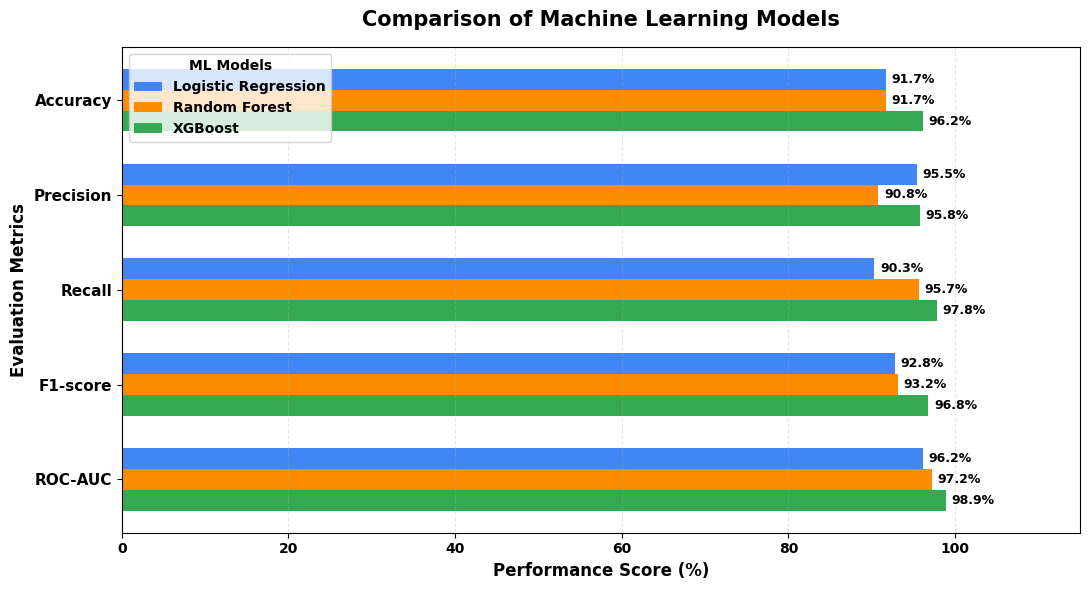

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Create comparison table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Accuracy": [lr_accuracy, rf_accuracy, xgb_accuracy],
    "Precision": [lr_precision, rf_precision, xgb_precision],
    "Recall": [lr_recall, rf_recall, xgb_recall],
    "F1-score": [lr_f1, rf_f1, xgb_f1],
    "ROC-AUC": [lr_roc_auc, rf_roc_auc, xgb_roc_auc]
})

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

# Convert scores to percentage if values are between 0 and 1
if comparison[metrics].max().max() <= 1:
    comparison[metrics] *= 100

# 2. Display bold comparison table
print("MODEL PERFORMANCE COMPARISON")

display(
    comparison.style
    .format({m: "{:.2f}%" for m in metrics})
    .highlight_max(subset=metrics, axis=0, color="#b7e4c7")
    .set_properties(**{"font-weight": "bold", "text-align": "center"})
    .set_table_styles([
        {"selector": "th", "props": [("font-weight", "bold"),
                                     ("text-align", "center")]},
        {"selector": "caption", "props": [("font-weight", "bold"),
                                          ("font-size", "14px")]}
    ])
)

# 3. Horizontal bar plot
fig, ax = plt.subplots(figsize=(11, 6))

colors = {
    "Logistic Regression": "#4285F4",
    "Random Forest": "#FB8C00",
    "XGBoost": "#34A853"
}

y = np.arange(len(metrics))
bar_height = 0.22

for i, model in enumerate(comparison["Model"]):
    values = comparison.loc[
        comparison["Model"] == model, metrics
    ].iloc[0].values

    positions = y + (i - 1) * bar_height

    bars = ax.barh(
        positions,
        values,
        height=bar_height,
        color=colors[model],
        label=model
    )

    # Bold percentage labels on bars
    labels = [f"{v:.1f}%" for v in values]
    ax.bar_label(
        bars,
        labels=labels,
        padding=4,
        fontsize=9,
        fontweight="bold"
    )

# 4. Bold plot text
ax.set_yticks(y)
ax.set_yticklabels(metrics, fontweight="bold", fontsize=11)
ax.set_xlabel("Performance Score (%)", fontweight="bold", fontsize=12)
ax.set_ylabel("Evaluation Metrics", fontweight="bold", fontsize=12)

ax.set_title(
    "Comparison of Machine Learning Models",
    fontweight="bold",
    fontsize=15,
    pad=15
)

ax.tick_params(axis="x", labelsize=10)
for label in ax.get_xticklabels():
    label.set_fontweight("bold")

legend = ax.legend(title="ML Models", fontsize=10)
legend.get_title().set_fontweight("bold")
for label in legend.get_texts():
    label.set_fontweight("bold")

ax.set_xlim(0, 115)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgboost_model
}

plt.figure(figsize=(8, 6))

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)

    plt.plot(fpr, tpr, linewidth=2,
             label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


ValueError: could not convert string to float: 'female'